<a href="https://colab.research.google.com/github/jmora420-hue/Ciencia_de_datos/blob/main/Continuaci%C3%B3n_An%C3%A1lisis_Lol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import requests
import pandas as pd
import time
from google.colab import files

API_KEY = "RGAPI-a0a782d7-12ec-4a63-a769-55c7e4f9daf5"
headers = {"X-Riot-Token": API_KEY}

def safe_request(url):
    while True:
        res = requests.get(url, headers=headers)
        if res.status_code == 429:
            retry_after = int(res.headers.get("Retry-After", 5))
            print(f"   [Pausa API] Esperando {retry_after} segs...")
            time.sleep(retry_after + 1)
        else:
            return res

def extraer_todo_aatrox(game_name, tag_line, region="americas", target_count=10):
    url_account = f"https://{region}.api.riotgames.com/riot/account/v1/accounts/by-riot-id/{game_name}/{tag_line}"
    puuid = safe_request(url_account).json().get("puuid")

    datos_resumen = []
    datos_timeline = []

    start_index = 0
    match_count = 0
    colas_validas = [400, 420, 430, 440, 490]

    print(f"Buscando {target_count} partidas de {game_name} con Aatrox TOP...")

    while match_count < target_count:
        url_match_ids = f"https://{region}.api.riotgames.com/lol/match/v5/matches/by-puuid/{puuid}/ids?start={start_index}&count=50"
        match_ids = safe_request(url_match_ids).json()

        if not match_ids: break

        for match_id in match_ids:
            if match_count >= target_count: break

            info = safe_request(f"https://{region}.api.riotgames.com/lol/match/v5/matches/{match_id}").json().get("info", {})
            if info.get("queueId") not in colas_validas: continue

            for p in info.get("participants", []):
                if p["puuid"] == puuid and p["championName"] == "Aatrox" and p.get("teamPosition") == "TOP":
                    match_count += 1
                    participant_id = p["participantId"]

                    # --- 1. EXTRACCIÓN DE RESUMEN FINAL ---
                    retos = p.get("challenges", {})
                    minutos = info["gameDuration"] / 60
                    cs_total = p["totalMinionsKilled"] + p["neutralMinionsKilled"]
                    items = [p[f"item{i}"] for i in range(6) if p[f"item{i}"] != 0]

                    try:
                        runa = p["perks"]["styles"][0]["selections"][0]["perk"]
                    except:
                        runa = "Desconocida"

                    datos_resumen.append({
                        "Partida": f"Partida {match_count}",
                        "Resultado": "Victoria" if p["win"] else "Derrota",
                        "Minutos": round(minutos, 1),
                        "KDA": f"{p['kills']}/{p['deaths']}/{p['assists']}",
                        "Ratio KDA": round((p["kills"] + p["assists"]) / max(1, p["deaths"]), 2),
                        "KP %": round(retos.get('killParticipation', 0) * 100, 1),
                        "Solo Kills": retos.get("soloKills", 0),
                        "Placas": retos.get("turretPlatesTaken", 0),
                        "CS / Min": round(cs_total / minutos, 1),
                        "Oro / Min": round(retos.get("goldPerMinute", 0), 1),
                        "Daño / Min": round(retos.get("damagePerMinute", 0), 1),
                        "Daño a Objetivos": p["damageDealtToObjectives"],
                        "Daño Recibido": p["totalDamageTaken"],
                        "Curación Total": p["totalHeal"],
                        "IDs Objetos Finales": items,
                        "ID Runa": runa
                    })

                    # --- 2. EXTRACCIÓN DE TIMELINE MINUTO A MINUTO ---
                    timeline_url = f"https://{region}.api.riotgames.com/lol/match/v5/matches/{match_id}/timeline"
                    frames = safe_request(timeline_url).json()["info"]["frames"]

                    for frame in frames:
                        minuto = frame["timestamp"] // 60000
                        estado = frame["participantFrames"][str(participant_id)]

                        # Buscar compras en los eventos de este minuto
                        objetos_comprados = []
                        for evento in frame.get("events", []):
                            if evento["type"] == "ITEM_PURCHASED" and evento["participantId"] == participant_id:
                                objetos_comprados.append(evento["itemId"])

                        datos_timeline.append({
                            "Partida": f"Partida {match_count}",
                            "Minuto": minuto,
                            "Nivel": estado["level"],
                            "Oro Total": estado["totalGold"],
                            "Súbditos (CS)": estado["minionsKilled"] + estado["jungleMinionsKilled"],
                            "IDs Objetos Comprados": objetos_comprados if objetos_comprados else "Ninguno"
                        })

                    print(f" -> Guardada Partida {match_count}/10")
                    break

        start_index += 50

    return pd.DataFrame(datos_resumen), pd.DataFrame(datos_timeline)

df_resumen, df_timeline = extraer_todo_aatrox("Rabbids3000", "LAN", target_count=10)

# Guardar localmente
df_resumen.to_csv('rabbids_resumen.csv', index=False)
df_timeline.to_csv('rabbids_timeline.csv', index=False)
files.download('rabbids_resumen.csv')
files.download('rabbids_timeline.csv')

print("Extracción completada con éxito.")

Buscando 10 partidas de Rabbids3000 con Aatrox TOP...
 -> Guardada Partida 1/10
 -> Guardada Partida 2/10
 -> Guardada Partida 3/10
 -> Guardada Partida 4/10
 -> Guardada Partida 5/10
 -> Guardada Partida 6/10
 -> Guardada Partida 7/10
 -> Guardada Partida 8/10
 -> Guardada Partida 9/10
 -> Guardada Partida 10/10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Extracción completada con éxito.


In [4]:
!pip install statsmodels
!pip install wquantiles

In [25]:
import pandas as pd
import numpy as np
from scipy.stats import trim_mean
from statsmodels import robust
import wquantiles
import seaborn as sns
import matplotlib.pyplot as plt
df_timeline.head(10)

,Partida,Minuto,Nivel,Oro Total,Súbditos (CS),IDs Objetos Comprados
0,Partida 1,0,1,500,0,Ninguno
1,Partida 1,1,1,500,0,"[1055, 2003]"
2,Partida 1,2,2,755,8,Ninguno
3,Partida 1,3,4,1429,14,Ninguno
4,Partida 1,4,5,1765,24,Ninguno
5,Partida 1,5,5,2111,27,"[3133, 1036]"
6,Partida 1,6,6,2436,37,Ninguno
7,Partida 1,7,7,2978,48,Ninguno
8,Partida 1,8,8,3250,57,Ninguno
9,Partida 1,9,8,3517,66,"[3134, 1001, 1029]"


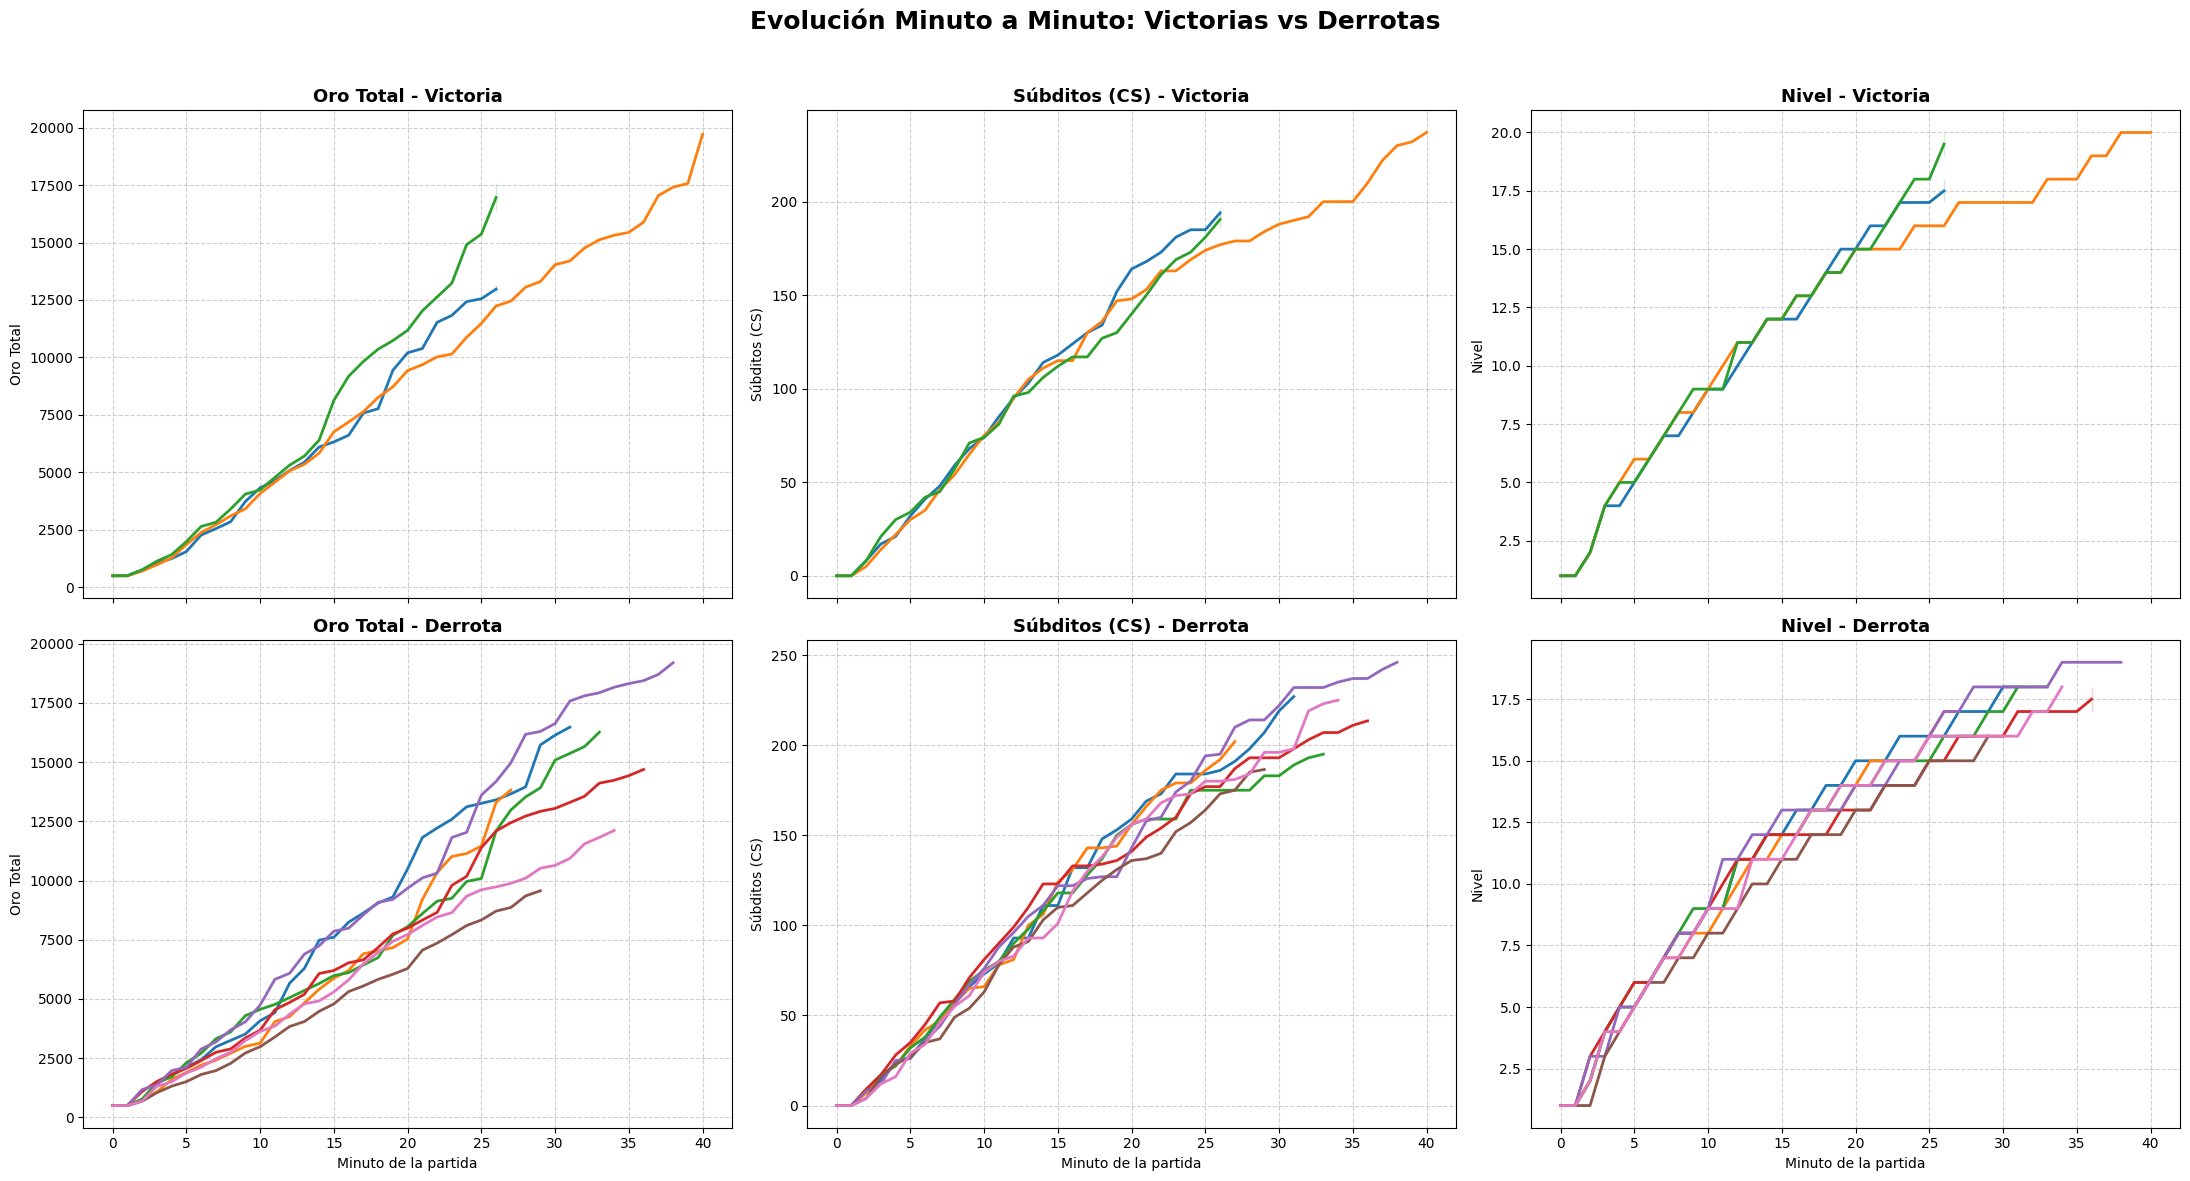

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cruzar los datos: Le pasamos el 'Resultado' del df_resumen al df_timeline
if 'Resultado' not in df_timeline.columns:
    mapa_resultados = dict(zip(df_resumen['Partida'], df_resumen['Resultado']))
    df_timeline['Resultado'] = df_timeline['Partida'].map(mapa_resultados)

# 2. Configurar la cuadrícula (2 filas x 3 columnas)
fig, axes = plt.subplots(2, 3, figsize=(22, 12), sharex=True)
fig.suptitle('Evolución Minuto a Minuto: Victorias vs Derrotas', fontsize=18, fontweight='bold')

resultados = ['Victoria', 'Derrota']
metricas = ['Oro Total', 'Súbditos (CS)', 'Nivel']

# 3. Dibujar cada gráfica
for i, res in enumerate(resultados):
    df_filtrado = df_timeline[df_timeline['Resultado'] == res]

    for j, metrica in enumerate(metricas):
        ax = axes[i, j]

        # Solo dibujar si hay partidas con ese resultado
        if not df_filtrado.empty:
            sns.lineplot(
                data=df_filtrado, x='Minuto', y=metrica,
                hue='Partida', palette='tab10', linewidth=2, ax=ax
            )

        ax.set_title(f'{metrica} - {res}', fontweight='bold', fontsize=13)
        ax.set_xlabel('Minuto de la partida')
        ax.set_ylabel(metrica)
        ax.grid(linestyle='--', alpha=0.6)

        # Quitamos las leyendas individuales para que no estorben la vista (opcional)
        if ax.get_legend() is not None:
            ax.get_legend().remove()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [9]:
df_rabbids = df_resumen.copy()

In [10]:
#Reemplazamos Victorias por un 1 y derrotas por un 0, para manejarlos como un bit binario
df_rabbids['Resultado'] = df_rabbids['Resultado'].replace({'Victoria': 1, 'Derrota': 0})

#Dividir la columna 'KDA' en 'Kills', 'Deaths' y 'Assists'
df_rabbids[['Kills', 'Deaths', 'Assists']] = df_rabbids['KDA'].str.split('/', expand=True).astype(float)

df_rabbids.sample(10)

/tmp/ipykernel_1307/3468290925.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_rabbids['Resultado'] = df_rabbids['Resultado'].replace({'Victoria': 1, 'Derrota': 0})


,Partida,Resultado,Minutos,KDA,Ratio KDA,KP %,Solo Kills,Placas,CS / Min,Oro / Min,Daño / Min,Daño a Objetivos,Daño Recibido,Curación Total,IDs Objetos,ID Runa,Kills,Deaths,Assists
0,Partida 1,0,31.8,12/4/5,4.25,73.9,4,17,7.1,519.3,1045.0,12496,34539,17865,"[2517, 6697, 6333, 3047, 3033, 3133]",8010,12.0,4.0,5.0
2,Partida 3,0,33.3,16/7/2,2.57,50.0,9,7,5.8,488.4,1235.2,10873,48291,22291,"[2517, 3111, 6697, 3161, 6333, 3155]",8010,16.0,7.0,2.0
5,Partida 6,1,40.4,20/6/6,4.33,52.0,5,10,5.9,489.4,1828.1,12395,71597,40234,"[2517, 6697, 3047, 3161, 6333, 3156]",8010,20.0,6.0,6.0
3,Partida 4,0,36.7,8/8/4,1.50,41.4,4,11,5.8,401.8,1322.0,24438,51206,22394,"[6333, 6692, 3047, 3161, 3156]",8010,8.0,8.0,4.0
6,Partida 7,0,38.3,18/10/4,2.20,57.9,11,17,6.4,501.1,1295.8,21383,64747,26785,"[3156, 6697, 3047, 3161, 6333, 3033]",8010,18.0,10.0,4.0
4,Partida 5,1,26.9,10/4/9,4.75,54.3,8,14,7.3,488.7,1197.4,14741,28970,15195,"[1037, 6697, 3047, 6692, 3161, 3133]",8010,10.0,4.0,9.0
9,Partida 10,0,34.6,5/8/4,1.12,32.1,4,6,6.5,353.8,774.8,10515,40668,13470,"[1055, 6695, 3047, 3033, 3161, 3155]",8010,5.0,8.0,4.0
8,Partida 9,0,29.4,2/7/5,1.00,28.0,1,4,6.4,326.7,1053.7,4148,37968,15812,"[1055, 6692, 3047, 3161, 3035, 1036]",8010,2.0,7.0,5.0
1,Partida 2,0,27.4,11/5/3,2.80,73.7,4,7,7.4,507.3,1119.6,6262,28898,13282,"[1037, 6697, 3047, 6333, 2517, 2021]",8010,11.0,5.0,3.0
7,Partida 8,1,26.9,26/1/5,31.00,75.6,15,15,7.2,651.2,1901.0,22691,31299,24909,"[1055, 3161, 3047, 6333, 6694, 2517]",8010,26.0,1.0,5.0


In [11]:
#Definir manualmente el vector de columnas a analizar (excluyendo Resultado, ID Runa e IDs Objetos)
cols_analizar = [
    'Minutos', 'Ratio KDA', 'Solo Kills', 'Placas',
    'CS / Min', 'Oro / Min', 'Daño / Min', 'Daño a Objetivos',
    'Daño Recibido', 'Curación Total', 'Kills', 'Deaths', 'Assists'
]

#Calcular medidas de tendencia central
print("=== MEDIDAS DE TENDENCIA CENTRAL (Rabbids3000) ===")
print("\n--- Media ---")
print(df_rabbids[cols_analizar].mean())

print("\n--- Mediana ---")
print(df_rabbids[cols_analizar].median())

print("\n--- Moda ---")
print(df_rabbids[cols_analizar].mode().iloc[0])

=== MEDIDAS DE TENDENCIA CENTRAL (Rabbids3000) ===

--- Media ---
Minutos                32.570
Ratio KDA               5.552
Solo Kills              6.500
Placas                 10.800
CS / Min                6.580
Oro / Min             472.770
Daño / Min           1277.260
Daño a Objetivos    13994.200
Daño Recibido       43818.300
Curación Total      21223.700
Kills                  12.800
Deaths                  6.000
Assists                 4.700
dtype: float64

--- Mediana ---
Minutos                32.550
Ratio KDA               2.685
Solo Kills              4.500
Placas                 10.500
CS / Min                6.450
Oro / Min             489.050
Daño / Min           1216.300
Daño a Objetivos    12445.500
Daño Recibido       39318.000
Curación Total      20078.000
Kills                  11.500
Deaths                  6.500
Assists                 4.500
dtype: float64

--- Moda ---
Minutos                26.9
Ratio KDA               1.0
Solo Kills              4.0
Placas   

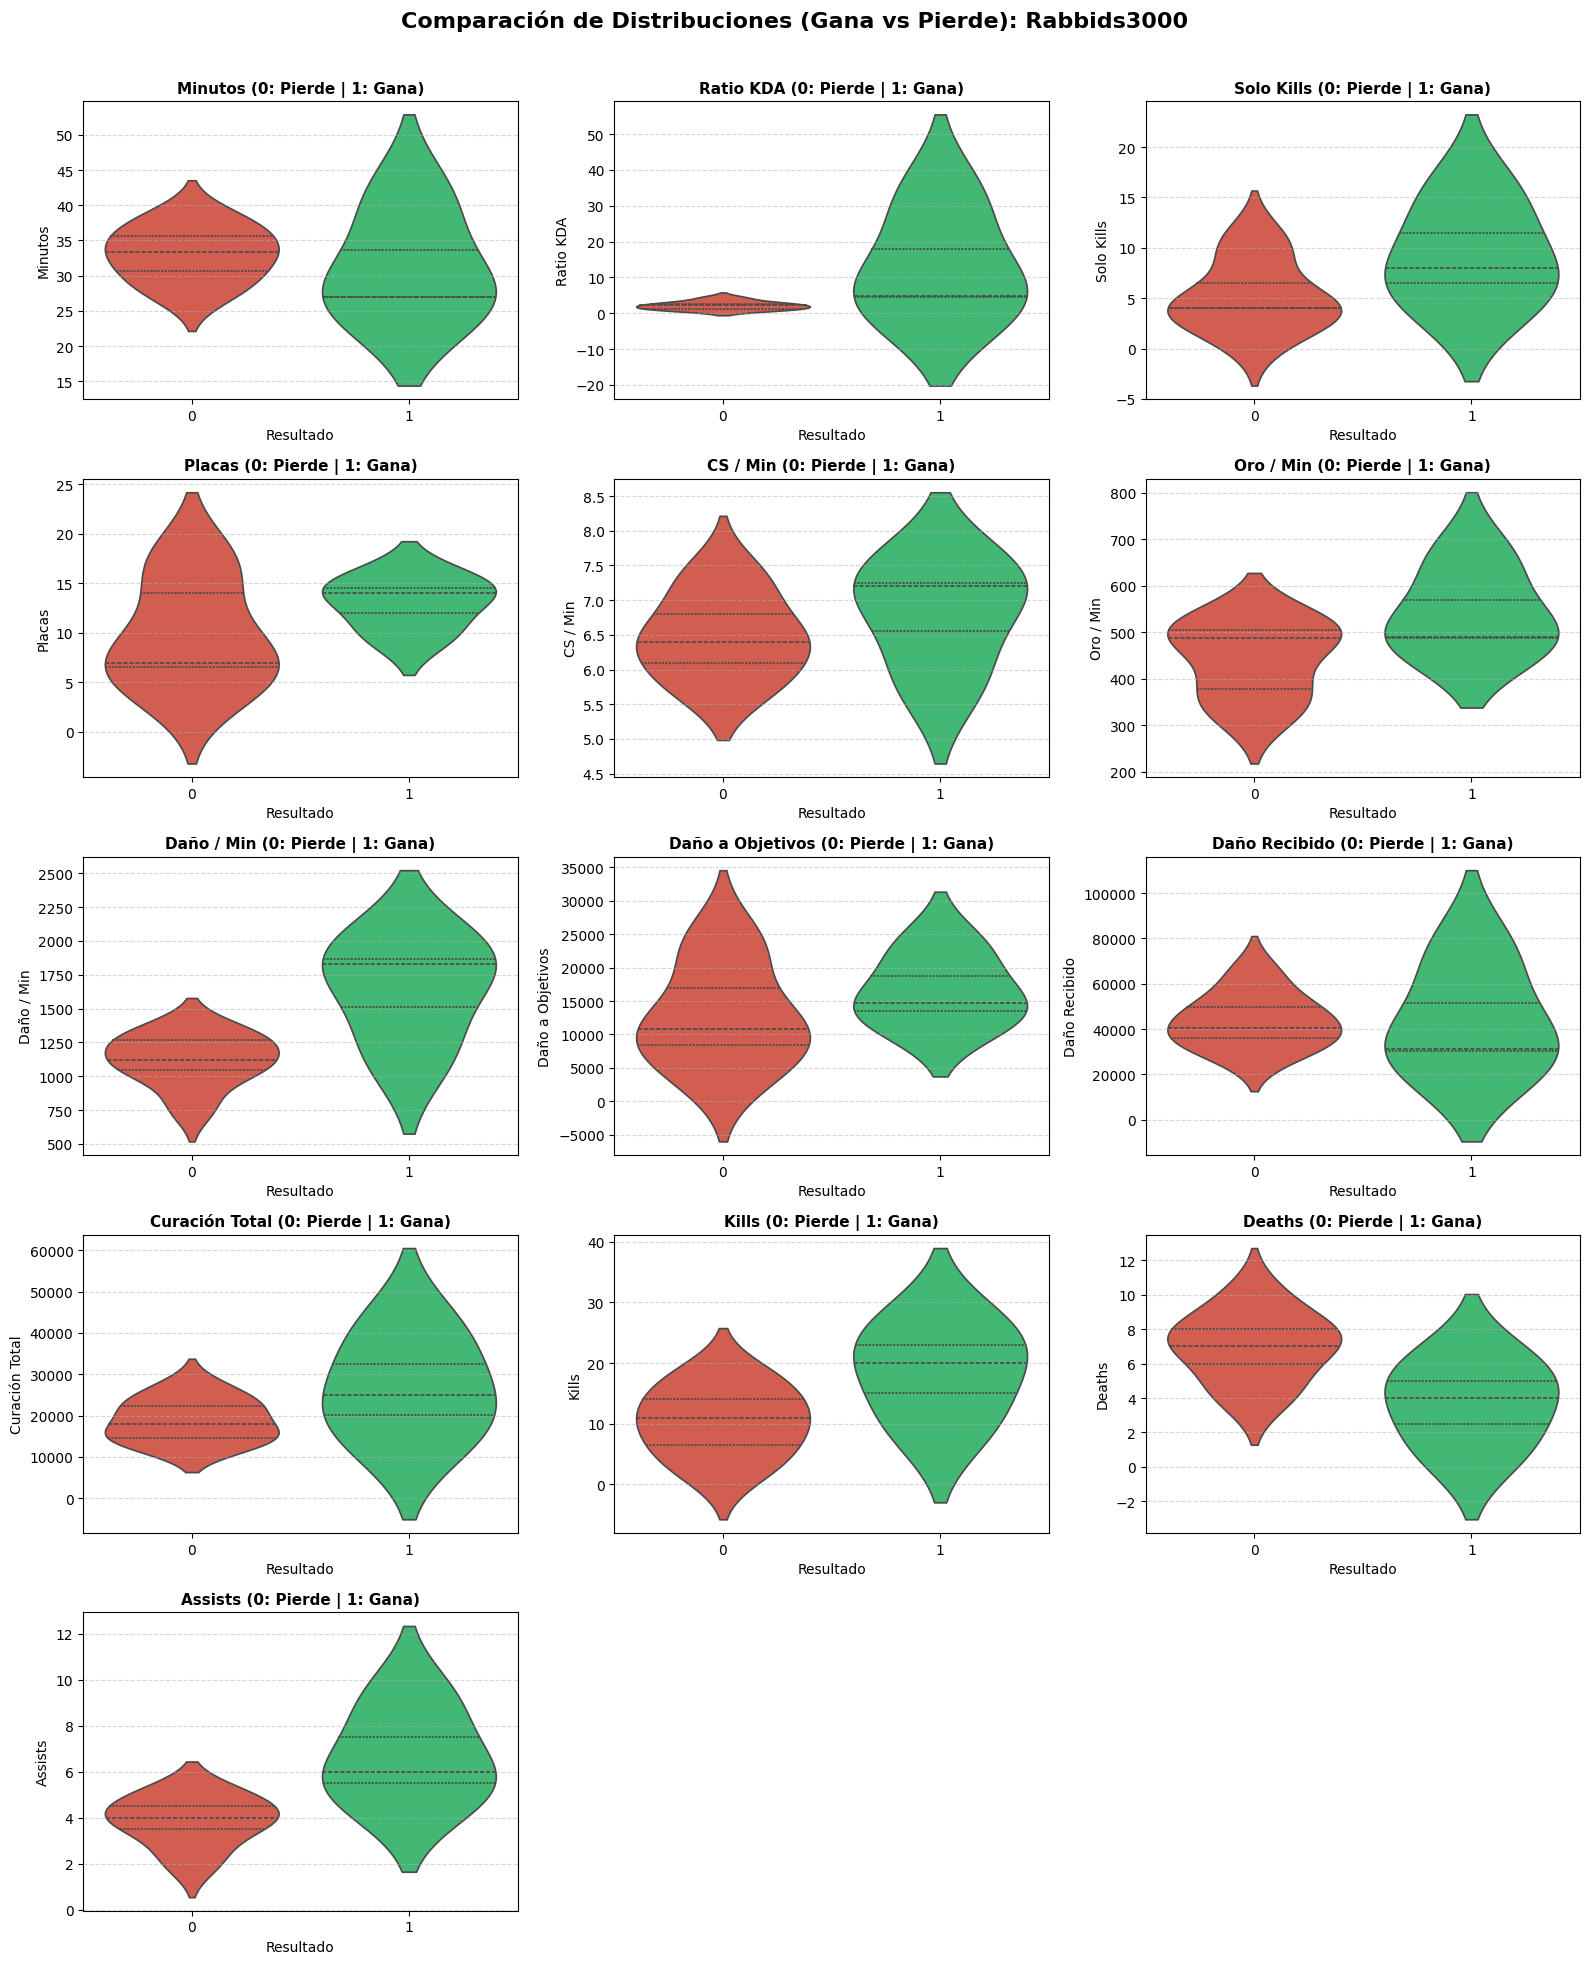

In [12]:
# COMPARACIÓN DE DISTRIBUCIONES: VICTORIAS VS DERROTAS DE RABBIDS3000
fig, axes = plt.subplots(5, 3, figsize=(16, 20))
fig.suptitle('Comparación de Distribuciones (Gana vs Pierde): Rabbids3000', fontsize=16, fontweight='bold')

axes_flat = axes.flatten()

for i, col in enumerate(cols_analizar):
    ax = axes_flat[i]

    sns.violinplot(
        x='Resultado',
        y=col,
        hue='Resultado',
        data=df_rabbids,
        ax=ax,
        palette=['#e74c3c', '#2ecc71'],  # Rojo para Derrota (0), Verde para Victoria (1)
        legend=False,
        inner='quartile'
    )

    ax.set_title(f'{col} (0: Pierde | 1: Gana)', fontweight='bold', fontsize=11)
    ax.set_xlabel('Resultado')
    ax.set_ylabel(col)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

# Ocultar los subgráficos que sobren de la cuadrícula
for j in range(len(cols_analizar), len(axes_flat)):
    fig.delaxes(axes_flat[j])

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [13]:
import ast

print(type(df_rabbids["IDs Objetos"][0]))

if isinstance(df_rabbids["IDs Objetos"][0], str):
  df_rabbids["IDs Objetos"]=df_rabbids["IDs Objetos"].apply(ast.literal_eval)

df_rabbids["IDs Objetos"].head()

<class 'list'>


,IDs Objetos
0,"[2517, 6697, 6333, 3047, 3033, 3133]"
1,"[1037, 6697, 3047, 6333, 2517, 2021]"
2,"[2517, 3111, 6697, 3161, 6333, 3155]"
3,"[6333, 6692, 3047, 3161, 3156]"
4,"[1037, 6697, 3047, 6692, 3161, 3133]"


In [14]:
import requests

# Versión más reciente del juego
version=requests.get("https://ddragon.leagueoflegends.com/api/versions.json").json()[0]

# Catálogo de objetos en español
url="https://ddragon.leagueoflegends.com/cdn/"+version+"/data/es_MX/item.json"
items=requests.get(url).json()["data"]

print("Versión:", version)
print("Objetos en el catálogo:", len(items))

Versión: 16.22.1
Objetos en el catálogo: 863


In [15]:
import re

nombres={}
descripcion_limpia={}
stats={}

for id_item in items:
  numero=int(id_item)
  texto=items[id_item]["description"]

  nombres[numero]=items[id_item]["name"]
  descripcion_limpia[numero]=re.sub("<.*?>"," ",texto).strip()

  # Solo la parte de atributos (antes de la pasiva)
  if "</stats>" in texto:
    parte_stats=texto.split("</stats>")[0]
  else:
    parte_stats=""
  stats[numero]=re.sub("<.*?>"," ",parte_stats).strip()

print(nombres[3047])
print(stats[3047])

Punteras de Acero Revestidas
25  de Armadura  45  de Velocidad de Movimiento


In [16]:
objetos=df_rabbids["IDs Objetos"].explode()

for id_item in objetos.unique():
  print(id_item, "-", nombres.get(id_item,"NO ENCONTRADO"))
  print("   ", stats.get(id_item,""))

2517 - Hambre Infinita
    65  de Daño de Ataque  5%  de Omnivampirismo  20%  de Tenacidad
6697 - Arrogancia
    55  de Daño de Ataque  18  de Letalidad  10  de Aceleración de Habilidad
6333 - Danza de la Muerte
    60  de Daño de Ataque  50  de Armadura  15  de Aceleración de Habilidad
3047 - Punteras de Acero Revestidas
    25  de Armadura  45  de Velocidad de Movimiento
3033 - Recordatorio Mortal
    35  de Daño de Ataque  30%  de Penetración de Armadura  25%  de Probabilidad de Golpe Crítico
3133 - Martillo de Guerra de Caulfield
    20  de Daño de Ataque  10  de Aceleración de Habilidad
1037 - Picacha
    25  de Daño de Ataque
2021 - Excavador de Túneles
    15  de Daño de Ataque  250  de Vida
3111 - Botas de Mercurio
    20  de Resistencia Mágica  45  de Velocidad de Movimiento  30%  de Tenacidad
3161 - Lanza de Shojin
    45  de Daño de Ataque  450  de Vida
3155 - Sorbechizos
    25  de Daño de Ataque  25  de Resistencia Mágica
6692 - Eclipse
    60  de Daño de Ataque  15  de Ac

In [17]:
conteo_objetos=objetos.map(nombres).value_counts()
print("Total de partidas:", len(df_rabbids))
conteo_objetos

Total de partidas: 10


,count
IDs Objetos,
Punteras de Acero Revestidas,9
Lanza de Shojin,8
Danza de la Muerte,7
Arrogancia,6
Hambre Infinita,5
Recordatorio Mortal,3
Fauces de Malmortius,3
Espada de Doran,3
Eclipse,3


In [18]:
top=objetos.value_counts().head(10)

tabla=pd.DataFrame({
    "Objeto": top.index.map(nombres),
    "Veces": top.values,
    "% de partidas": (top.values/len(df_rabbids)*100).round(1)
})
display(tabla)

# Descripción de los 5 favoritos
for id_item in top.index[:5]:
  print(nombres.get(id_item), "->", descripcion_limpia.get(id_item))
  print()

,Objeto,Veces,% de partidas
0,Punteras de Acero Revestidas,9,90.0
1,Lanza de Shojin,8,80.0
2,Danza de la Muerte,7,70.0
3,Arrogancia,6,60.0
4,Hambre Infinita,5,50.0
5,Recordatorio Mortal,3,30.0
6,Fauces de Malmortius,3,30.0
7,Espada de Doran,3,30.0
8,Eclipse,3,30.0
9,Martillo de Guerra de Caulfield,2,20.0


Punteras de Acero Revestidas -> 25  de Armadura  45  de Velocidad de Movimiento    Revestimiento  Reduce el daño recibido de los ataques en un 10%.

Lanza de Shojin -> 45  de Daño de Ataque  450  de Vida    Fuerza del Dragón   Obtienes 25 de Aceleración de Habilidad para habilidades básicas.   Voluntad Enfocada   Al infligir daño con habilidades, el daño de las habilidades y de la pasiva de tu campeón aumenta en un 3% durante 6 seg. (Se acumula 4 veces).

Danza de la Muerte -> 60  de Daño de Ataque  50  de Armadura  15  de Aceleración de Habilidad    Ignorar Dolor  Un porcentaje del daño recibido se distribuye a lo largo de 3 seg.   Desafiar  Cuando un campeón muere en un lapso de 3 seg después de que le hayas infligido daño, se disipa el daño restante de  Ignorar Dolor  y recuperas  vida  a lo largo de 2 seg.

Arrogancia -> 55  de Daño de Ataque  18  de Letalidad  10  de Aceleración de Habilidad    Eminencia  Cuando un campeón al que le infligiste daño muere en 3 seg, obtienes  0 de D

In [19]:
atributos={
    "Daño de ataque": ["daño de ataque"],
    "Poder de habilidad": ["poder de habilidad"],
    "Armadura": ["armadura"],
    "Resistencia mágica": ["resistencia mágica"],
    "Vida": ["vida"],
    "Velocidad de ataque": ["velocidad de ataque"],
    "Celeridad de habilidad": ["celeridad de habilidad","aceleración de habilidad"],
    "Crítico": ["crítico"],
    "Penetración": ["penetración"],
    "Velocidad de movimiento": ["velocidad de movimiento"],
    "Curación / robo de vida": ["curación","robo de vida","vampirismo"]
}

conteo={}
for atributo in atributos:
  conteo[atributo]=0
  for id_item in objetos:
    texto=stats.get(id_item,"").lower()
    for palabra in atributos[atributo]:
      if palabra in texto:
        conteo[atributo]=conteo[atributo]+1
        break

resultado=pd.Series(conteo).sort_values(ascending=False)
print(resultado)
print()
print("En % de objetos comprados:")
print((resultado/len(objetos)*100).round(1))

Daño de ataque             49
Celeridad de habilidad     22
Armadura                   21
Vida                       12
Velocidad de movimiento    10
Curación / robo de vida     8
Resistencia mágica          6
Penetración                 5
Crítico                     3
Poder de habilidad          0
Velocidad de ataque         0
dtype: int64

En % de objetos comprados:
Daño de ataque             83.1
Celeridad de habilidad     37.3
Armadura                   35.6
Vida                       20.3
Velocidad de movimiento    16.9
Curación / robo de vida    13.6
Resistencia mágica         10.2
Penetración                 8.5
Crítico                     5.1
Poder de habilidad          0.0
Velocidad de ataque         0.0
dtype: float64


In [20]:
from sklearn.feature_extraction.text import CountVectorizer

descripciones_usadas=objetos.map(descripcion_limpia).fillna("")

palabras_vacias=["cuando","puede","hasta","durante","después","mientras","otros","segundos",
                 "contra","cada","sobre","entre","desde","estos","estas","luego","tras",
                 "campeón","obtienes","muere","recibido","largo","infligir","infligido",
                 "ignorar","habilidades","además","como","pero","solo","esto","esta","este",
                 "dado","esos","unos","tipo","cual","mismo","misma","hacia","según","nivel",
                 "aumenta","aumentas","ganas","pasiva","activa","único","unico"]

# Palabras de 4 letras o más (así entra "daño", "vida", "oro")
cv=CountVectorizer(max_features=15, token_pattern=r"\b\w{4,}\b", stop_words=palabras_vacias)
matriz=cv.fit_transform(descripciones_usadas)

df_vec=pd.DataFrame(matriz.toarray(), columns=cv.get_feature_names_out())
df_vec.sum().sort_values(ascending=False)

,0
daño,132
ataque,60
aceleración,35
habilidad,35
vida,25
armadura,21
omnivampirismo,16
dolor,14
ataques,12
reduce,11


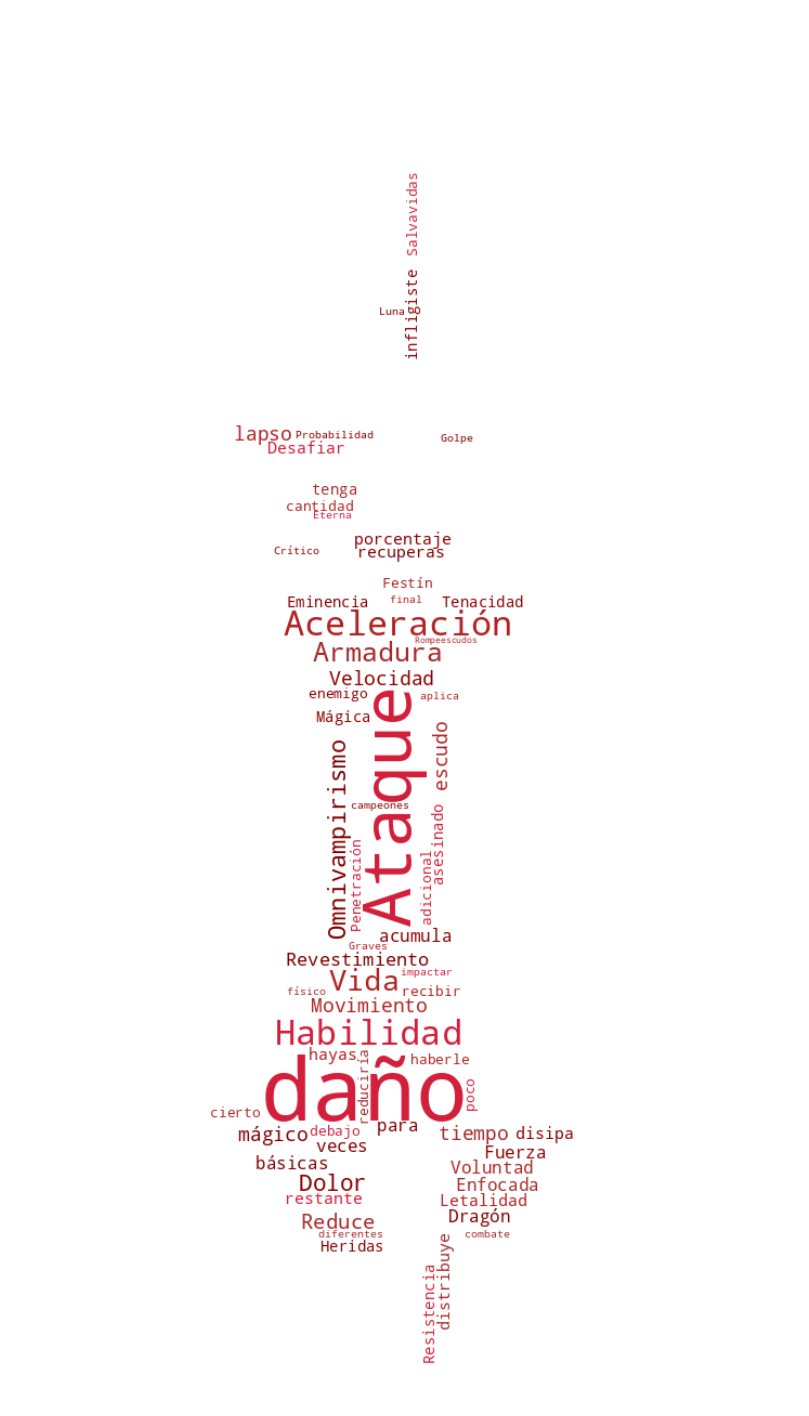

In [21]:
from wordcloud import WordCloud
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random

# Texto: descripciones de los objetos que compra
texto_limpio = " ".join(descripciones_usadas)

# Máscara: pasamos la imagen a escala de grises
imagen = Image.open("/content/drive/MyDrive/Colab Notebooks/Espada.webp").convert("L")
mascara_gris = np.array(imagen)

# Ajustamos la máscara:
mascara = np.where(mascara_gris > 150, 255, 0)

# Función de color personalizada para garantizar tonos rojos oscuros de alto contraste
def color_rojo_oscuro(word, font_size, position, orientation, random_state=None, **kwargs):
    # Tonos: Rojo Oscuro, Carmesí, Marrón Rojizo, Rojo Sangre
    colores = ["#800000", "#8B0000", "#A52A2A", "#B22222", "#D21F3C"]
    return random.choice(colores)

nube = WordCloud(
    background_color="white",
    mask=mascara,
    color_func=color_rojo_oscuro, # Aplicamos los colores de alto contraste
    stopwords=set(palabras_vacias),
    min_word_length=4,
    min_font_size=8,              # Evita que las palabras sean exageradamente pequeñas
    max_font_size=80,             # Controla el tamaño máximo para mantener balance
    collocations=False,
    max_words=120,                # Reducimos ligeramente el tope para evitar saturación ilegible
    width=1000,
    height=1200,
    random_state=42
).generate(texto_limpio)

plt.figure(figsize=(10, 12), dpi=150) # Mayor tamaño y DPI para máxima nitidez
plt.imshow(nube, interpolation='bilinear')
plt.axis("off")
plt.show()

In [22]:
#Posición promedio de sus 10 objetos favoritos (1 = lo compra primero, 6 = lo compra último)
top=objetos.value_counts().head(10)

posicion_promedio={}
for id_item in top.index:
  lugares=[]
  for lista in df_rabbids["IDs Objetos"]:
    if id_item in lista:
      lugares.append(lista.index(id_item)+1)
  posicion_promedio[nombres[id_item]]=round(sum(lugares)/len(lugares),1)

pd.Series(posicion_promedio).sort_values()

,0
Espada de Doran,1.0
Arrogancia,2.2
Eclipse,2.7
Hambre Infinita,2.8
Punteras de Acero Revestidas,3.1
Danza de la Muerte,3.9
Fauces de Malmortius,4.0
Lanza de Shojin,4.0
Recordatorio Mortal,5.0
Martillo de Guerra de Caulfield,6.0


In [23]:
#Build típica
print("Build típica:")
for id_item in objetos.value_counts().head(6).index:
  print("-", nombres[id_item])

Build típica:
- Punteras de Acero Revestidas
- Lanza de Shojin
- Danza de la Muerte
- Arrogancia
- Hambre Infinita
- Recordatorio Mortal


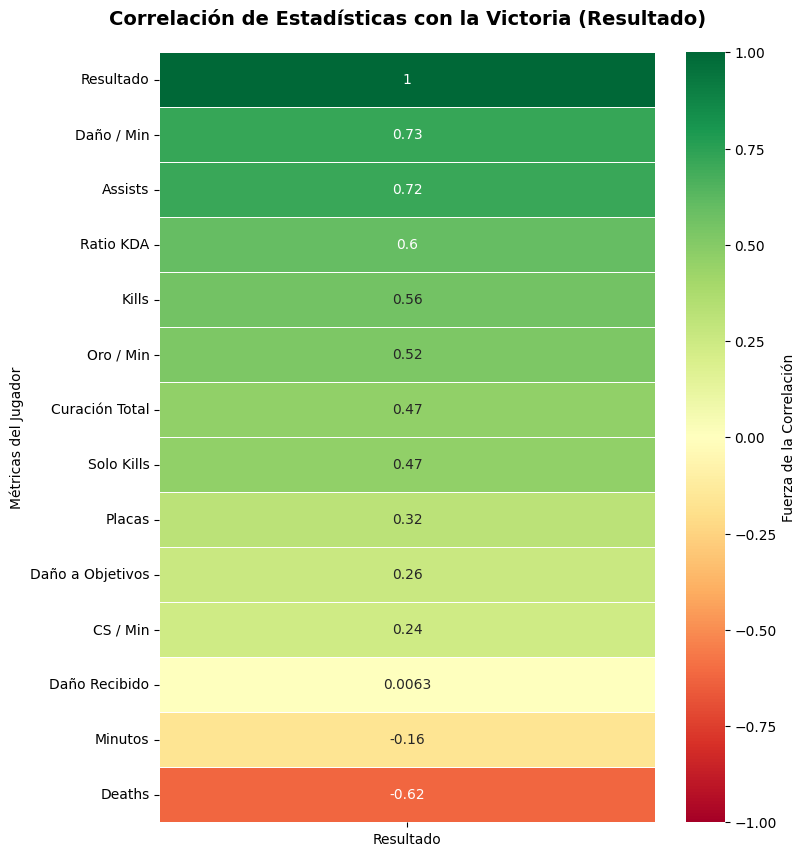

=== CONCLUSIONES CLAVE PARA TU PROFE ===
- Los valores cercanos a 1 indican que a mayor cantidad de esa estadística, más probabilidad de Victoria.
- Los valores cercanos a -1 (rojo) indican que esa estadística se asocia fuertemente con la Derrota.


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Seleccionamos las variables numéricas más interesantes para la correlación incluyendo el Resultado (1 o 0)
columnas_correlacion = [
    'Resultado', 'Minutos', 'Ratio KDA', 'Solo Kills', 'Placas',
    'CS / Min', 'Oro / Min', 'Daño / Min', 'Daño a Objetivos',
    'Daño Recibido', 'Curación Total', 'Kills', 'Deaths', 'Assists'
]

# Calcular la matriz de correlación
matriz_corr = df_rabbids[columnas_correlacion].corr()

# Extraer la correlación específicamente con el 'Resultado' para ver qué influye más en ganar (1) o perder (0)
corr_con_resultado = matriz_corr[['Resultado']].sort_values(by='Resultado', ascending=False)

# Dibujar el mapa de calor
plt.figure(figsize=(8, 10))
sns.heatmap(
    corr_con_resultado,
    annot=True,
    cmap='RdYlGn',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={'label': 'Fuerza de la Correlación'}
)

plt.title('Correlación de Estadísticas con la Victoria (Resultado)', fontweight='bold', fontsize=14, pad=20)
plt.ylabel('Métricas del Jugador')
plt.show()

print("- Los valores cercanos a 1 indican que a mayor cantidad de esa estadística, más probabilidad de Victoria.")
print("- Los valores cercanos a -1 (rojo) indican que esa estadística se asocia fuertemente con la Derrota.")